<a href="https://colab.research.google.com/github/Eshwar754/AI_Programs/blob/main/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Dataset shape: (569, 30)
Target shape: (569,)
Features names:
['mean radius' 'mean texture' 'mean perimeter' 'mean area'
 'mean smoothness' 'mean compactness' 'mean concavity'
 'mean concave points' 'mean symmetry' 'mean fractal dimension'
 'radius error' 'texture error' 'perimeter error' 'area error'
 'smoothness error' 'compactness error' 'concavity error'
 'concave points error' 'symmetry error' 'fractal dimension error'
 'worst radius' 'worst texture' 'worst perimeter' 'worst area'
 'worst smoothness' 'worst compactness' 'worst concavity'
 'worst concave points' 'worst symmetry' 'worst fractal dimension']
Class names:
['malignant' 'benign']
Input shape: (569, 30)
Output shape: (569,)
Training data: (398, 30)
Testing data: (171, 30)
Training shape: (398, 30)
Testing shape: (171, 30)
Predicted values:
[0 1 1 0 0 0 1 0 1 0 1 1 0 1 1 0 0 1 1 1 1 1 1 0 0 1 1 1 0 0 1 0 1 1 0 1 1
 1 1 1 1 0 1 1 1 1 1 1 1 0 1 1 0 0 1 1 0 1 1 1 0 0 0 1 1 1 1 0 1 1 0 0 0 0
 1 1 1 1 0 1 1 1 0 1 0 1 1 0 0 0 0 

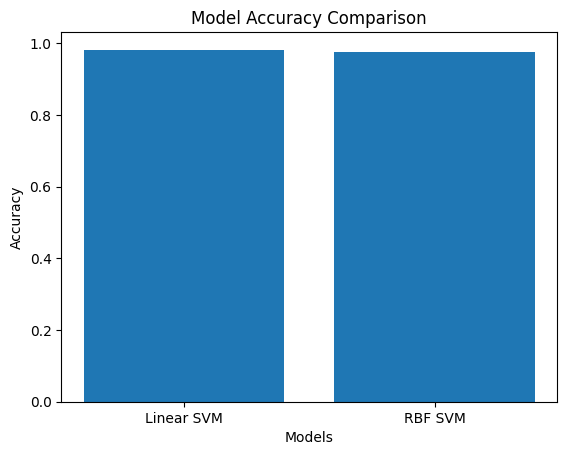

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import classification_report, accuracy_score,confusion_matrix

# Load dataset
data = load_breast_cancer()
X = data.data
y = data.target
print("Dataset shape:",X.shape)
print("Target shape:",y.shape)
print("Features names:")
print(data.feature_names)
print("Class names:")
print(data.target_names)

df=pd.DataFrame(X,columns=data.feature_names)
df['Target']=y
df.head()

X=df.drop('Target',axis=1)
y=df['Target']
print("Input shape:",X.shape)
print("Output shape:",y.shape)

X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.3,random_state=42,stratify=y)
print("Training data:",X_train.shape)
print("Testing data:",X_test.shape)

scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

print("Training shape:",X_train_scaled.shape)
print("Testing shape:",X_test_scaled.shape)

linear_svm=SVC(kernel='linear',C=1.0)
linear_svm.fit(X_train_scaled,y_train)
y_pred_linear=linear_svm.predict(X_test_scaled)
print("Predicted values:")
print(y_pred_linear)
print("Actutal Values:")
print(y_test.values)

accuracy_linear=accuracy_score(y_test,y_pred_linear)
print("Linear SVM Accuracy:",accuracy_linear)

cm_linear=confusion_matrix(y_test,y_pred_linear)
print("Confusion Matrix:")
print(cm_linear)


print(classification_report(y_test,y_pred_linear, target_names=data.target_names))

rbf_svm=SVC(kernel='rbf',C=1.0)
rbf_svm.fit(X_train_scaled,y_train)
y_pred_rbf=rbf_svm.predict(X_test_scaled)
print("Predicted values:")
print(y_pred_rbf)
print("Actutal Values:")
print(y_test.values)

accuracy_rbf=accuracy_score(y_test,y_pred_rbf)
print("RBF SVM Accuracy:",accuracy_rbf)

cm_rbf=confusion_matrix(y_test,y_pred_rbf)
print("Confusion Matrix:")
print(cm_rbf)

print(classification_report(y_test,y_pred_rbf, target_names=data.target_names))

print("Linear SVM Accuracy:",accuracy_linear)
print("RBF SVM Accuracy:",accuracy_rbf)
if accuracy_linear>accuracy_rbf:
    print("Linear SVM is better than RBF SVM")
elif accuracy_rbf>accuracy_linear:
    print("RBF SVM is better than Linear SVM")
else:
    print("Both SVM are equal")
models=['Linear SVM','RBF SVM']
accuracy_scores=[accuracy_linear,accuracy_rbf]
plt.bar(models,accuracy_scores)
plt.xlabel('Models')
plt.ylabel('Accuracy')
plt.title('Model Accuracy Comparison')
plt.show()